# Sparse submatrix detection and recovery
**Amrit Chadha and Faris Doughan · STAT 236**

*Google Colab AI was used to help create these simulations, as well as to format the output nicely as you can see here*

## Settings


| Setting | Choice |
|---|---|
| Matrix and block sizes | $n=16$ with $k=3,5,8$ (here $\sqrt n=4$ and $n^{2/3}\approx6.3$); $n=512$ with $k=12,42,107$ (here $\sqrt n\approx22.6$ and $n^{2/3}=64$) |
| Data | Independent $N(0,1)$ noise, with $\mu$ added to a $k\times k$ block whose rows and columns are drawn uniformly at random in each trial |
| Trials | 300 per $(n,k,\mu)$, so each estimated proportion has standard error at most $\sqrt{.25/300}\approx.029$ |
| Detection signals | Six values of $\mu$ that give the sum theoretical power $.05,.25,.5,.75,.9,.99$ |
| Recovery signals | $0.5,0.75,1,1.25,1.5,2$ times the recovery reference from Section 3.1 of the report |
| Level | $.05$ for each test. The combined test uses $.025$ for each component, so its level is at most $.05$ |
| Sum cutoff | $\Phi^{-1}(.95)\approx1.645$, exact because the statistic is $N(0,1)$ under $H_0$ |
| Max cutoff | $\Phi^{-1}\big((.95)^{1/n^2}\big)$, exact because the $n^2$ entries are independent under $H_0$ |
| Scan computation | Exact. For a fixed set of $k$ rows, the best $k$ columns are those with the largest column sums over those rows, so we enumerate the $\binom nk$ row sets, at most $\binom{16}{8}=12{,}870$. Only run at $n=16$ |
| Scan cutoff | From 1,500 separate noise matrices. We reject when the statistic exceeds the $\lceil 1501(1-\alpha)\rceil$-th smallest null value (the 1,426th for $\alpha=.05$ and the 1,464th for $\alpha=.025$), which keeps the level at most $\alpha$ |
| Exhaustive recovery | The $k\times k$ block with the largest sum, found by the same enumeration. Only run at $n=16$ |
| Spectral recovery | Leading left and right singular vectors $\hat u,\hat v$, then the $k$ rows and $k$ columns with the largest scores $X\hat v$ and $X^\top\hat u$. Unlike Algorithm 1 of Cai, Liang and Rakhlin, this uses $k$ |
| Soft thresholding | $\eta_t(x)=\operatorname{sign}(x)(\lvert x\rvert-t)_+$ with $t=\sqrt{\log(n/k^2)}$, only when $k^2<n$. This gives $t\approx0.76$ for $n=16,k=3$ and $t\approx1.13$ for $n=512,k=12$. We did not tune $t$ |
| Singular vectors | Full SVD (`numpy.linalg.svd`) when $n\le64$; otherwise ARPACK (`scipy.sparse.linalg.svds`) with a starting vector of ones and tolerance $10^{-5}$. Signs are chosen so that $\hat u$ has a positive sum |
| Recovery error | 1 if any row or column is wrong, 0 otherwise |
| Known quantities | The scan and all recovery methods receive the true $k$. The noise variance is known to be 1 |
| Reproducibility | Seed 236 for the simulated matrices and 1236 for the scan calibration. BLAS is limited to one thread |

In [1]:
from functools import cache
from itertools import combinations
from math import ceil, comb

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.sparse.linalg import svds
from threadpoolctl import threadpool_limits

blas_limit = threadpool_limits(limits=1)
rng = np.random.default_rng(236)
null_rng = np.random.default_rng(1236)
REPS, CALIBRATION_REPS, ALPHA = 300, 1500, 0.05
target_powers = np.array([ALPHA, 0.25, 0.5, 0.75, 0.9, 0.99])
detectors = ['sum', 'scan', 'max', 'sum+scan']
recovery_methods = ['exhaustive', 'spectral', 'soft spectral']
colors = {'sum':'C0', 'scan':'C1', 'max':'C2', 'sum+scan':'C3',
          'exhaustive':'C0', 'spectral':'C1', 'soft spectral':'C2'}
configs = [(16, 3), (16, 5), (16, 8),
           (512, 12), (512, 42), (512, 107)]

In [2]:
import sys
import scipy, matplotlib
print('Python', sys.version.split()[0])
for module in (np, scipy, pd, matplotlib):
    print(module.__name__, module.__version__)

Python 3.13.18
numpy 2.4.6
scipy 1.16.3
pandas 2.2.3
matplotlib 3.10.0


## Functions

The functions below simulate one matrix, compute the exact scan, and run the spectral methods. `scan` returns both the scan statistic and the maximizing block

In [3]:
def make_matrix(n, k, mu):
    X = rng.standard_normal((n, n))
    rows = np.sort(rng.choice(n, k, replace=False))
    cols = np.sort(rng.choice(n, k, replace=False))
    X[np.ix_(rows, cols)] += mu
    return X, rows, cols


@cache
def row_sets(n, k):
    if comb(n, k) > 20000:
        raise ValueError('Exact scanning is too large for this configuration.')
    rows = np.array(list(combinations(range(n), k)))
    weights = np.zeros((len(rows), n))
    weights[np.arange(len(rows))[:, None], rows] = 1
    return rows, weights


def scan(X, k):
    rows, weights = row_sets(len(X), k)
    column_sums = weights @ X
    sums = np.partition(column_sums, len(X)-k, axis=1)[:, -k:].sum(axis=1)
    best = sums.argmax()
    cols = np.sort(np.argpartition(column_sums[best], -k)[-k:])
    return sums[best] / k, (rows[best], cols)


def leading_pair(Y):
    if len(Y) <= 64:
        U, _, Vt = np.linalg.svd(Y, full_matrices=False)
    else:
        U, _, Vt = svds(Y, k=1, which='LM', v0=np.ones(len(Y)), tol=1e-5)
    u, v = U[:, 0].copy(), Vt[0].copy()
    if u.sum() < 0:
        u, v = -u, -v
    return u, v


def spectral(X, k, t=0.0):
    Y = X if t == 0 else np.sign(X)*np.maximum(np.abs(X)-t, 0)
    u, v = leading_pair(Y)
    rows = np.sort(np.argsort(Y @ v)[-k:])
    cols = np.sort(np.argsort(Y.T @ u)[-k:])
    return rows, cols


def recovery_error(estimate, rows, cols):
    return int(not (np.array_equal(estimate[0], rows)
                    and np.array_equal(estimate[1], cols)))

The sum and max use cutoffs from their known noise distributions, while the scan cutoff is chosen from 1,500 separate noise matrices.
The detection level is .05, with .025 assigned to each component of the combined test.
The recovery experiment also records the detection decisions, so we can compare detection and recovery at the same signals.

In [4]:
def upper_cutoff(values, alpha):
    rank = ceil((len(values)+1)*(1-alpha))-1
    return np.sort(values)[rank]


@cache
def cutoffs(n, k, exact):
    c = {'sum': norm.isf(ALPHA),
         'max': norm.ppf((1-ALPHA)**(1/n**2))}
    if exact:
        values = [scan(null_rng.standard_normal((n, n)), k)[0]
                  for _ in range(CALIBRATION_REPS)]
        c.update(scan=upper_cutoff(values, ALPHA),
                 sum_half=norm.isf(ALPHA/2),
                 scan_half=upper_cutoff(values, ALPHA/2))
    return c


def detect(X, k, c, exact):
    total = X.sum()/len(X)
    decision = {'sum': total > c['sum'], 'max': X.max() > c['max']}
    estimate = None
    if exact:
        value, estimate = scan(X, k)
        decision.update(scan=value > c['scan'],
                        **{'sum+scan': total > c['sum_half'] or value > c['scan_half']})
    return decision, estimate


def experiment(n, k, mu, exact=False, recovery=False):
    c = cutoffs(n, k, exact)
    hits = {name: 0 for name in (detectors if exact else ['sum', 'max'])}
    wrong = {}
    if recovery:
        wrong = {'spectral': 0, 'soft spectral': 0 if k*k < n else np.nan}
        if exact:
            wrong['exhaustive'] = 0
    t = np.sqrt(np.log(n/k**2)) if k*k < n else 0
    for _ in range(REPS):
        X, rows, cols = make_matrix(n, k, mu)
        decision, estimate = detect(X, k, c, exact)
        for name in hits:
            hits[name] += decision[name]
        if recovery:
            wrong['spectral'] += recovery_error(spectral(X, k), rows, cols)
            if k*k < n:
                wrong['soft spectral'] += recovery_error(spectral(X, k, t), rows, cols)
            if exact:
                wrong['exhaustive'] += recovery_error(estimate, rows, cols)
    return {'n': n, 'k': k, 'mu': mu,
            **{name: value/REPS for name, value in hits.items()},
            **{name: value/REPS for name, value in wrong.items()}}

## 1. Detection

We increase $\mu$ at each $(n,k)$, choosing six signals that give the sum theoretical powers from $.05$ to $.99$.
The dashed curve is its exact Gaussian power, $1-\Phi(\Phi^{-1}(.95)-\mu k^2/n)$, so we can compare the simulated results with this prediction.

Finished detection at n=16, k=3
Finished detection at n=16, k=5
Finished detection at n=16, k=8
Finished detection at n=512, k=12
Finished detection at n=512, k=42
Finished detection at n=512, k=107


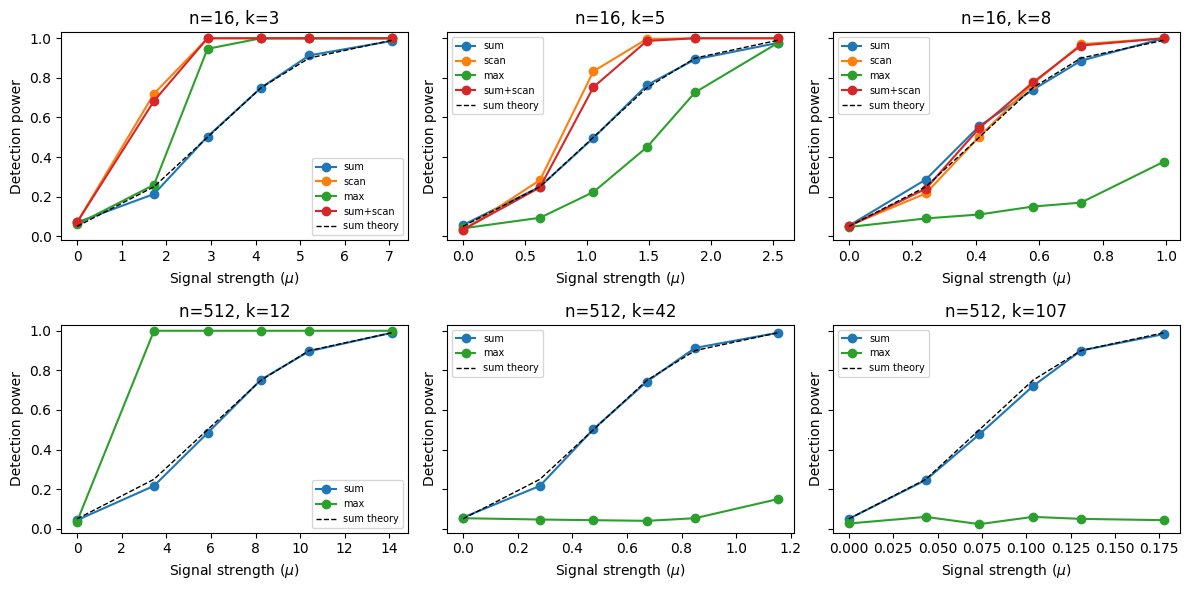

In [5]:
detection_results = []
for n, k in configs:
    signal_strengths = np.maximum(0, norm.isf(ALPHA)+norm.ppf(target_powers))*n/k**2
    for mu in signal_strengths:
        detection_results.append(experiment(n, k, mu, exact=n == 16))
    print(f'Finished detection at n={n}, k={k}')
detection_results = pd.DataFrame(detection_results)

fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharey=True)
for ax, (n, k) in zip(axes.flat, configs):
    points = detection_results.query('n == @n and k == @k')
    names = detectors if n == 16 else ['sum', 'max']
    for method in names:
        ax.plot(points.mu, points[method], 'o-', label=method, color=colors[method])
    ax.plot(points.mu, norm.sf(norm.isf(ALPHA)-points.mu*k**2/n),
            'k--', linewidth=1, label='sum theory')
    ax.set(title=f'n={n}, k={k}', ylim=(-.02, 1.03),
           xlabel=r'Signal strength ($\mu$)', ylabel='Detection power')
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig('detection_power.png', dpi=200, bbox_inches='tight')
plt.show()

In [6]:
# Simulated power next to the sum's theoretical power
detection_table = detection_results.copy()
detection_table.insert(3, 'sum theory',
                       norm.sf(norm.isf(ALPHA) - detection_table.mu*detection_table.k**2/detection_table.n))
detection_table.round(3)

,n,k,mu,sum theory,sum,scan,max,sum+scan
0,16,3,0.000,0.05,0.070,0.070,0.060,0.070
1,16,3,1.725,0.25,0.213,0.720,0.260,0.683
2,16,3,2.924,0.50,0.503,1.000,0.947,1.000
3,16,3,4.123,0.75,0.750,1.000,1.000,1.000
4,16,3,5.202,0.90,0.913,1.000,1.000,1.000
5,16,3,7.060,0.99,0.987,1.000,1.000,1.000
6,16,5,0.000,0.05,0.057,0.030,0.040,0.033
7,16,5,0.621,0.25,0.250,0.283,0.093,0.247
8,16,5,1.053,0.50,0.497,0.833,0.223,0.753
9,16,5,1.484,0.75,0.763,0.997,0.450,0.987


## 2. Recovery

We increase $\mu$ from half to twice the recovery boundary given in the report, counting any incorrect row or column as an error.


Finished recovery at n=16, k=3
Finished recovery at n=16, k=5
Finished recovery at n=16, k=8
Finished recovery at n=512, k=12
Finished recovery at n=512, k=42
Finished recovery at n=512, k=107


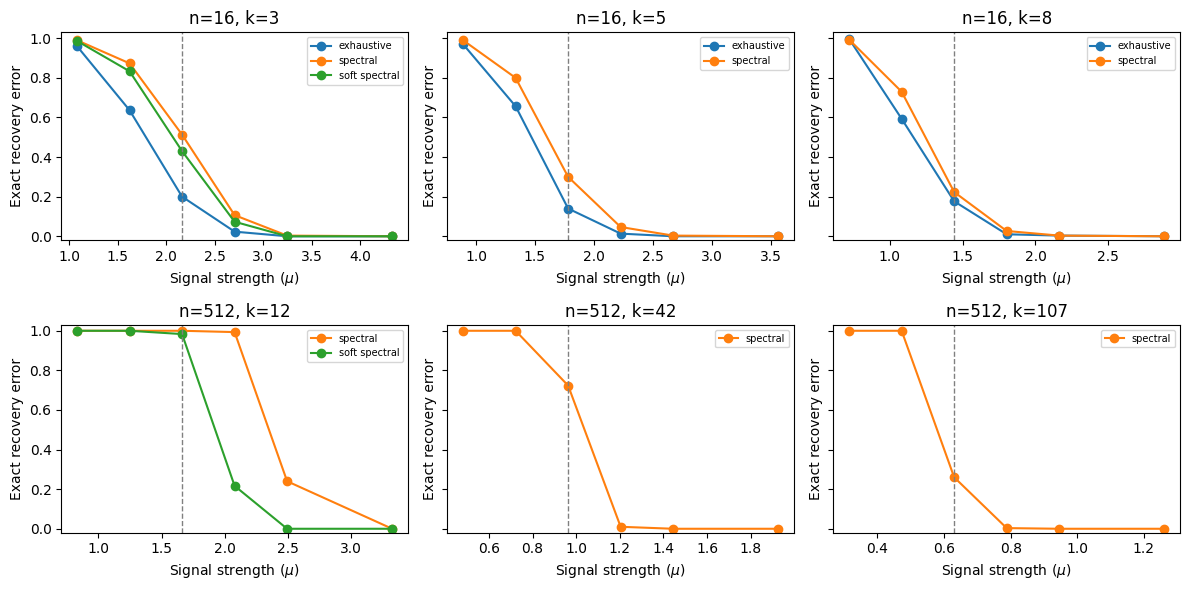

In [7]:
def recovery_reference(n, k):
    row_separation = (np.sqrt(2*np.log(k))+np.sqrt(2*np.log(n-k)))/np.sqrt(k)
    block_search = 2*np.sqrt(np.log(n/k)/k)
    return max(row_separation, block_search)


recovery_results = []
for n, k in configs:
    signal_strengths = recovery_reference(n, k)*np.array([0.5, 0.75, 1, 1.25, 1.5, 2])
    for mu in signal_strengths:
        recovery_results.append(experiment(n, k, mu, exact=n == 16, recovery=True))
    print(f'Finished recovery at n={n}, k={k}')
recovery_results = pd.DataFrame(recovery_results)

fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharey=True)
for ax, (n, k) in zip(axes.flat, configs):
    points = recovery_results.query('n == @n and k == @k')
    for method in recovery_methods:
        if method in points and points[method].notna().any():
            ax.plot(points.mu, points[method], 'o-', label=method, color=colors[method])
    ax.axvline(recovery_reference(n, k), color='0.5', linestyle='--', linewidth=1)
    ax.set(title=f'n={n}, k={k}', ylim=(-.02, 1.03),
           xlabel=r'Signal strength ($\mu$)', ylabel='Exact recovery error')
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig('recovery_error.png', dpi=200, bbox_inches='tight')
plt.show()

In [8]:
# Recovery error, with the detection decisions recorded at the same signals
recovery_table = recovery_results.copy()
recovery_table.insert(3, 'mu / reference',
                      recovery_table.mu / [recovery_reference(n, k)
                                           for n, k in zip(recovery_table.n, recovery_table.k)])
recovery_table.round(3)

,n,k,mu,mu / reference,sum,scan,max,sum+scan,spectral,soft spectral,exhaustive
0,16,3,1.082,0.50,0.143,0.250,0.103,0.217,0.990,0.987,0.960
1,16,3,1.623,0.75,0.250,0.660,0.287,0.627,0.873,0.833,0.637
2,16,3,2.163,1.00,0.327,0.973,0.580,0.940,0.513,0.430,0.200
3,16,3,2.704,1.25,0.443,1.000,0.850,1.000,0.107,0.073,0.023
4,16,3,3.245,1.50,0.630,1.000,0.990,1.000,0.003,0.000,0.000
5,16,3,4.327,2.00,0.820,1.000,1.000,1.000,0.000,0.000,0.000
6,16,5,0.891,0.50,0.337,0.620,0.180,0.547,0.990,NaN,0.970
7,16,5,1.336,0.75,0.607,0.983,0.297,0.970,0.800,NaN,0.657
8,16,5,1.782,1.00,0.867,1.000,0.617,1.000,0.300,NaN,0.140
9,16,5,2.227,1.25,0.973,1.000,0.923,1.000,0.047,NaN,0.013
